# ① 비밀번호 위험도 진단 모델: 데이터 분석과 학습 과정

**목표**: 비밀번호 문자열을 보고 "위험(쉽게 뚫림)"인지 "안전"인지 판단하는 딥러닝 분류기를 만든다.

| 단계 | 내용 | 사용 코드 |
|---|---|---|
| 1 | 데이터 설계 (왜 합성 데이터인가) | `src/password_risk/wordlists.py` |
| 2 | 학습/평가 데이터 생성 | `src/password_risk/generator.py` |
| 3 | 탐색적 데이터 분석(EDA) | `src/password_risk/rules.py` |
| 4 | 전처리와 모델 구조 | `src/password_risk/model.py` |
| 5 | 학습 | `src/password_risk/train.py` |
| 6 | 평가와 기준 모델 비교 | `src/password_risk/train.py` |
| 7 | 오류 분석과 한계 | `src/password_risk/predict.py` |

## 0. 환경 설정
**코랩에서 실행하는 방법**
1. 왼쪽 📁 파일 탭에 `login-guard-ai.zip`을 업로드합니다.
2. 이 노트북을 위에서부터 차례대로 실행합니다 (`런타임 → 모두 실행`).

필요한 라이브러리(torch, numpy, pandas, scikit-learn, matplotlib)는 코랩에 기본으로 설치되어 있습니다.
실제 계산 코드는 `src/` 폴더의 `.py` 파일에 있고, 이 노트북은 그 함수들을 불러와 **과정과 결과를 보여주는** 역할을 합니다.

In [1]:
# 환경 설정: 코랩이면 압축을 풀고, 로컬이면 프로젝트 루트로 이동
import os, sys, subprocess
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    ROOT = Path('/content/login-guard-ai')
    if not ROOT.exists():
        subprocess.run(['unzip', '-q', '-o', '/content/login-guard-ai.zip', '-d', '/content'], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('프로젝트 위치:', ROOT, '| 코랩:', IN_COLAB)

프로젝트 위치: c:\Users\human-16\Desktop\test\login-guard-ai | 코랩: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import config
from src.password_risk import rules
from src.password_risk.wordlists import BASE_WORDS, SAFE_WORDS, COMMON_PASSWORDS, KEYBOARD_WALKS, split_words
from src.password_risk.train import make_datasets, train_model, evaluate_model, plot_confusion, save_model

pd.set_option('display.max_colwidth', 40)
plt.rcParams['figure.dpi'] = 100
print('torch', torch.__version__, '| GPU 사용 가능:', torch.cuda.is_available())

torch 2.15.0+cpu | GPU 사용 가능: False


## 1. 데이터 설계: 왜 합성 데이터인가

실제 유출 비밀번호 DB(RockYou 등)는 **실존 인물의 개인정보**이므로 사용하지 않았다.
대신 보안 보고서에 반복적으로 나오는 "사람들이 흔히 만드는 비밀번호 유형"을 규칙으로 정리해 데이터를 합성했다.

- **위험(라벨 1)**: 흔한 비밀번호, 단어+연도/생일, `@`→`a` 같은 치환, 키보드 패턴(qwer), 숫자열, 짧은 문자열, 반복 문자
- **안전(라벨 0)**: 12~20자 무작위 문자열, 서로 무관한 단어 3~4개를 이은 문장형 비밀번호

**일반화 검증 장치**: 단어 목록을 학습용 75% / 평가용 25%로 나눈다.
평가 데이터에는 학습 때 **한 번도 본 적 없는 단어**만 나오므로, 모델이 단어를 외운 것이 아니라 "패턴"을 배웠는지 확인할 수 있다.

In [3]:
risky_tr, risky_te = split_words(BASE_WORDS)
safe_tr, safe_te = split_words(SAFE_WORDS)

lists = {
    '흔한 비밀번호': COMMON_PASSWORDS, '키보드 패턴': KEYBOARD_WALKS,
    '위험 단어 (학습용)': risky_tr, '위험 단어 (평가용)': risky_te,
    '안전 단어 (학습용)': safe_tr, '안전 단어 (평가용)': safe_te,
}
display(pd.DataFrame({'목록': lists.keys(),
                      '개수': [len(v) for v in lists.values()],
                      '예시': [', '.join(v[:6]) for v in lists.values()]}))
print('학습/평가 단어 겹침 (위험):', set(risky_tr) & set(risky_te) or '없음')
print('학습/평가 단어 겹침 (안전):', set(safe_tr) & set(safe_te) or '없음')

,목록,개수,예시
0,흔한 비밀번호,48,"123456, 123456789, 12345678, 1234567..."
1,키보드 패턴,19,"qwerty, qwer, asdf, asdfgh, zxcv, zx..."
2,위험 단어 (학습용),57,"love, sarang, saranghae, korea, seou..."
3,위험 단어 (평가용),20,"minsu, younghee, chulsoo, jihoon, su..."
4,안전 단어 (학습용),42,"maple, orbit, tundra, violet, canyon..."
5,안전 단어 (평가용),14,"lagoon, mosaic, nectar, obsidian, py..."


학습/평가 단어 겹침 (위험): 없음
학습/평가 단어 겹침 (안전): 없음


## 2. 데이터 생성

학습 40,000개, 평가 8,000개를 만든다. 위험:안전 = 1:1로 균형을 맞췄고, 시드를 고정해서 언제 실행해도 같은 데이터가 나온다.

In [4]:
train_data, test_data = make_datasets(n_train=40000, n_test=8000)
train_df = pd.DataFrame(train_data, columns=['password', 'label'])
test_df = pd.DataFrame(test_data, columns=['password', 'label'])
for d in (train_df, test_df):
    d['class'] = d.label.map({1: 'risky', 0: 'safe'})

print('학습:', train_df.shape, ' 평가:', test_df.shape)
display(pd.concat([train_df.label.value_counts().rename('학습'),
                   test_df.label.value_counts().rename('평가')], axis=1)
        .rename(index={1: '위험(1)', 0: '안전(0)'}))

학습: (40000, 3)  평가: (8000, 3)


,학습,평가
label,,
위험(1),20000,4000
안전(0),20000,4000


In [5]:
# 클래스별 예시
display(pd.concat([train_df[train_df.label == 1].head(8).reset_index(drop=True).password.rename('위험 예시'),
                   train_df[train_df.label == 0].head(8).reset_index(drop=True).password.rename('안전 예시')], axis=1))

,위험 예시,안전 예시
0,ANdGnCJ,otter-kelp-rav344en-Walrus@
1,qazwsx,embe293r!Basil!cobalt!harbor!
2,www333,K^-TsFA?q0Gs6
3,zzz555,Otter!peb490ble!Nimbus!summit+
4,monkey2006#,494Otter%heron%Pepper%marble*
5,721121,Prairie@copper@Pebb399le!
6,56789,Orbit*dune939*cobalt*jasper
7,!@#$,!XgZ+#YVMmsb7s


In [6]:
# 데이터 품질 확인: 중복과 학습/평가 겹침(데이터 누수)
dup = train_df.password.duplicated()
overlap = set(train_df.password) & set(test_df.password)
print(f'학습 데이터 중복 비율: {dup.mean():.1%}  (위험 {dup[train_df.label == 1].mean():.1%} / 안전 {dup[train_df.label == 0].mean():.1%})')
print(f'학습·평가에 동시에 나오는 비밀번호: {len(overlap)}개')
print('겹치는 예:', sorted(overlap)[:15])

학습 데이터 중복 비율: 18.0%  (위험 35.9% / 안전 0.0%)
학습·평가에 동시에 나오는 비밀번호: 402개
겹치는 예: ['!@#$', '!@#$!', '!@#$%^', '!@#$%^!', '!@#$%^1', '!@#$%^123', '!@#$1', '!@#$123', '0000', '00000', '000000', '0000000', '00000000', '012345678', '0123456789']


**해석**: 위험 쪽 중복은 대부분 `123456` 같은 "흔한 비밀번호" 목록에서 나온다. 실제로도 이런 비밀번호는 많은 사람이 똑같이 쓰기 때문에 현실과 맞는 특성이다.
학습·평가에 함께 나오는 것도 이런 흔한 비밀번호와 짧은 숫자열이 대부분이다. 단어 기반 비밀번호는 평가용 단어를 따로 썼기 때문에 겹치지 않는다.

## 3. 탐색적 데이터 분석 (EDA)

`rules.analyze()`로 각 비밀번호의 특징(길이, 문자 종류, 흔한 단어 포함 여부, 키보드 패턴 등)을 뽑아 위험/안전 그룹을 비교한다.
이 특징들은 나중에 **진단 결과의 근거**로 화면에 보여주고, LLM 코치에게도 (비밀번호 원문 대신) 이 특징만 보낸다.

In [7]:
def add_features(df):
    flags = df.password.apply(lambda p: rules.analyze(p)['flags']).apply(pd.Series)
    return pd.concat([df, flags], axis=1)

train_f = add_features(train_df)
test_f = add_features(test_df)
display(train_f.groupby('class')['length'].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
risky,20000.0,8.1,2.8,3.0,6.0,8.0,9.0,24.0
safe,20000.0,21.1,6.0,12.0,16.0,20.0,26.0,34.0


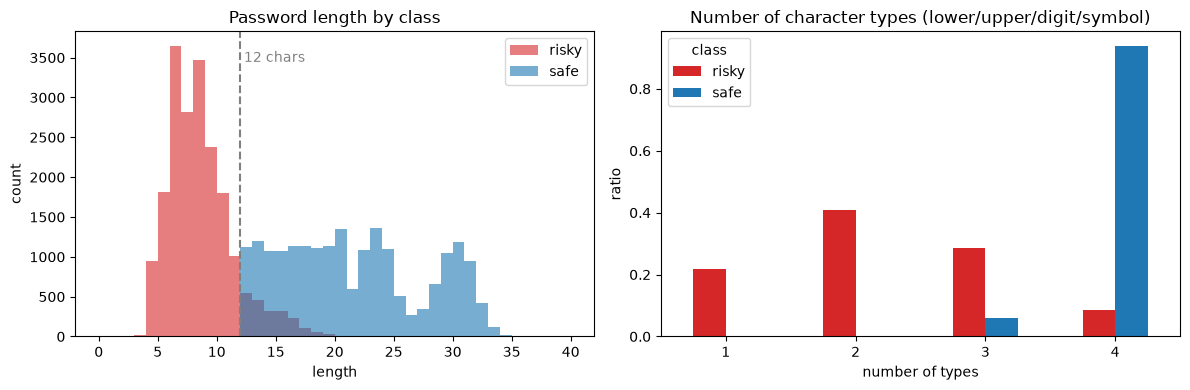

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(0, 41)
for c, color in [('risky', 'tab:red'), ('safe', 'tab:blue')]:
    axes[0].hist(train_f[train_f['class'] == c].length, bins=bins, alpha=0.6, label=c, color=color)
axes[0].set(title='Password length by class', xlabel='length', ylabel='count')
axes[0].axvline(12, ls='--', c='gray'); axes[0].text(12.3, axes[0].get_ylim()[1] * 0.9, '12 chars', color='gray')
axes[0].legend()

ct = pd.crosstab(train_f['n_classes'], train_f['class'], normalize='columns')
ct.plot.bar(ax=axes[1], color=['tab:red', 'tab:blue'], rot=0)
axes[1].set(title='Number of character types (lower/upper/digit/symbol)', xlabel='number of types', ylabel='ratio')
plt.tight_layout(); plt.show()

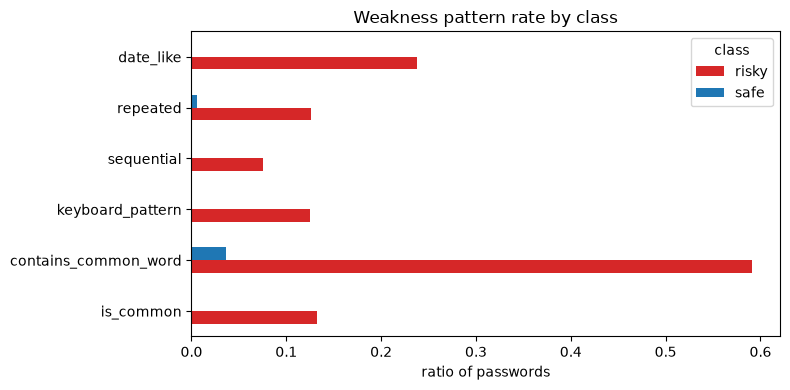

class,위험(%),안전(%)
is_common,13.2,0.0
contains_common_word,59.1,3.6
keyboard_pattern,12.5,0.0
sequential,7.5,0.0
repeated,12.6,0.6
date_like,23.8,0.0


In [9]:
flag_cols = ['is_common', 'contains_common_word', 'keyboard_pattern', 'sequential', 'repeated', 'date_like']
rate = train_f.groupby('class')[flag_cols].mean().T
ax = rate.plot.barh(figsize=(8, 4), color=['tab:red', 'tab:blue'])
ax.set(title='Weakness pattern rate by class', xlabel='ratio of passwords')
plt.tight_layout(); plt.show()
display((rate * 100).round(1).rename(columns={'risky': '위험(%)', 'safe': '안전(%)'}))

**EDA에서 알 수 있는 점**
- **길이**가 가장 강한 차이를 보인다. 안전 비밀번호는 모두 12자 이상이고, 위험 비밀번호는 대부분 12자 미만이다.
- 위험 비밀번호는 **문자 종류가 1~2개**인 경우가 많고, 안전 비밀번호는 3~4종류를 섞는다.
- 흔한 단어, 연도/생일, 키보드 패턴 같은 약점은 거의 위험 그룹에서만 나타난다.

⚠️ 그렇다면 "길이만 보면 되는 것 아닌가?"라는 의문이 생긴다. 이를 확인하기 위해 6장에서 **길이만 쓰는 기준 모델**, **규칙 점수 기준 모델**과 딥러닝 모델을 비교한다.

## 4. 전처리와 모델 구조

**전처리**: 비밀번호를 글자 단위로 쪼개 숫자 ID로 바꾼다. 출력 가능한 ASCII 95자는 1~95, 한글 등은 96, 빈 자리는 0(패딩)으로 채워 길이 32로 맞춘다.

**모델 (문자 단위 BiLSTM)**
1. `Embedding`: 글자 ID → 32차원 벡터
2. `BiLSTM`: 앞→뒤, 뒤→앞 두 방향으로 읽어 `love1998!` 같은 "단어+숫자+기호" 순서 패턴을 잡아낸다
3. 마지막 은닉 상태 + 길이 특징 → 완전연결층 → 위험 확률 (sigmoid)

In [10]:
from src.password_risk.model import PasswordRiskNet, encode

for pw in ['love1998!', 'Orbit-Velvet42']:
    ids, n = encode(pw, config.PW_MAX_LEN)
    print(f'{pw!r:18} 길이={n:2d}  →', ids[:16], '...')

net = PasswordRiskNet(max_len=config.PW_MAX_LEN)
print()
print(net)
print('학습 파라미터 수:', sum(p.numel() for p in net.parameters() if p.requires_grad))

'love1998!'        길이= 9  → [77, 80, 87, 70, 18, 26, 26, 25, 2, 0, 0, 0, 0, 0, 0, 0] ...
'Orbit-Velvet42'   길이=14  → [48, 83, 67, 74, 85, 14, 55, 70, 77, 87, 70, 85, 21, 19, 0, 0] ...

PasswordRiskNet(
  (emb): Embedding(97, 32, padding_idx=0)
  (lstm): LSTM(32, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Linear(in_features=129, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
학습 파라미터 수: 61665


## 5. 학습

- 손실 함수: Binary Cross Entropy (`BCEWithLogitsLoss`)
- 최적화: Adam, 학습률 0.001, 배치 256, 8 에폭
- 매 에폭마다 평가 데이터(처음 보는 단어) 정확도를 기록한다

CPU에서 1~3분 정도 걸린다.

In [11]:
%%time
model, history = train_model(train_data, test_data, epochs=8)
hist = pd.DataFrame(history)

[epoch 1] train_loss=0.1581  test_acc=0.9981


[epoch 2] train_loss=0.0046  test_acc=0.9994


[epoch 3] train_loss=0.0024  test_acc=0.9981


[epoch 4] train_loss=0.0013  test_acc=0.9988


[epoch 5] train_loss=0.0016  test_acc=0.9982


[epoch 6] train_loss=0.0010  test_acc=0.9974


[epoch 7] train_loss=0.0003  test_acc=0.9989


[epoch 8] train_loss=0.0003  test_acc=0.9994
CPU times: total: 8min 58s
Wall time: 2min 20s


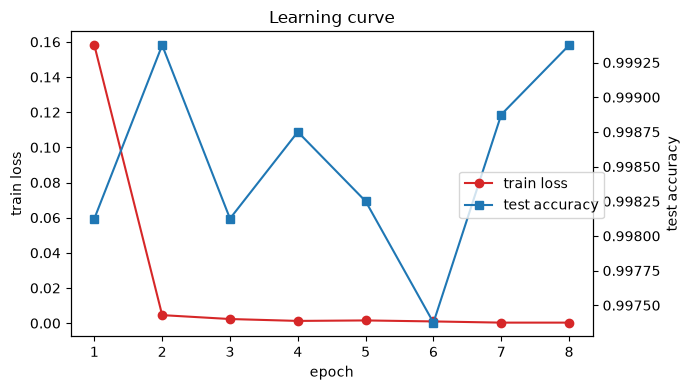

,epoch,train_loss,test_acc
0,1,0.1581,0.9981
1,2,0.0046,0.9994
2,3,0.0024,0.9981
3,4,0.0013,0.9988
4,5,0.0016,0.9982
5,6,0.0010,0.9974
6,7,0.0003,0.9989
7,8,0.0003,0.9994


In [12]:
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(hist.epoch, hist.train_loss, 'o-', c='tab:red', label='train loss')
ax1.set(xlabel='epoch', ylabel='train loss')
ax2 = ax1.twinx()
ax2.plot(hist.epoch, hist.test_acc, 's-', c='tab:blue', label='test accuracy')
ax2.set_ylabel('test accuracy')
fig.legend(loc='center right', bbox_to_anchor=(0.88, 0.5))
ax1.set_title('Learning curve')
plt.tight_layout(); plt.show()
display(hist.round(4))

## 6. 평가

### 6-1. 딥러닝 모델 성능
위험을 양성(1)으로 보고 정확도, 정밀도(위험이라고 한 것 중 진짜 위험), 재현율(진짜 위험 중 잡아낸 비율), F1을 계산한다.

In [13]:
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

prob, y_true, metrics = evaluate_model(model, test_data)
pred = (prob > 0.5).astype(int)
display(pd.DataFrame([metrics]).drop(columns='note').round(4))
print(classification_report(y_true, pred, target_names=['safe', 'risky'], digits=4))

,accuracy,precision,recall,f1,n_test
0,0.9994,0.9997,0.999,0.9994,8000


              precision    recall  f1-score   support

        safe     0.9990    0.9998    0.9994      4000
       risky     0.9997    0.9990    0.9994      4000

    accuracy                         0.9994      8000
   macro avg     0.9994    0.9994    0.9994      8000
weighted avg     0.9994    0.9994    0.9994      8000



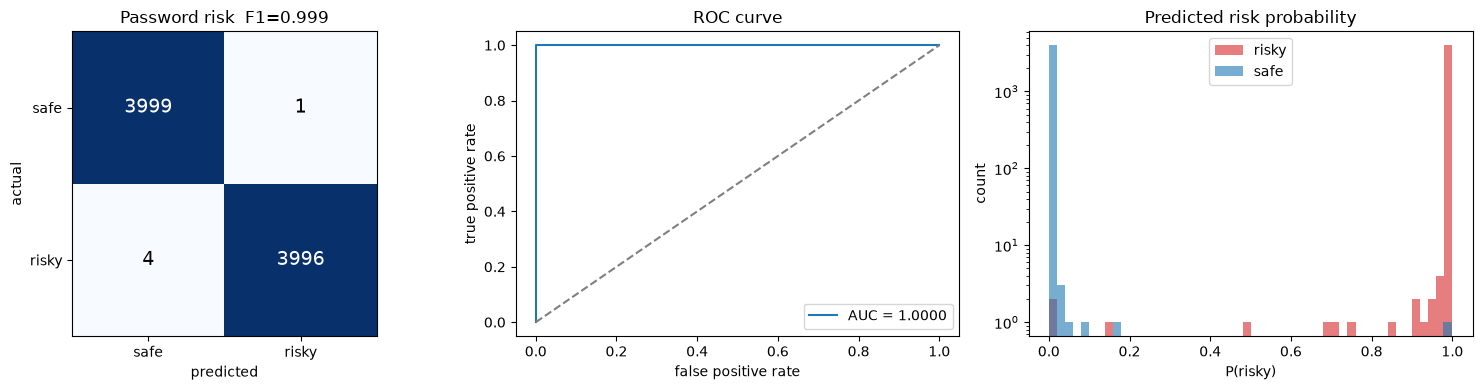

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_confusion(y_true, pred, metrics['f1'], ax=axes[0])

fpr, tpr, _ = roc_curve(y_true, prob)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_true, prob):.4f}')
axes[1].plot([0, 1], [0, 1], '--', c='gray')
axes[1].set(title='ROC curve', xlabel='false positive rate', ylabel='true positive rate'); axes[1].legend()

axes[2].hist(prob[y_true == 1], bins=50, alpha=0.6, color='tab:red', label='risky')
axes[2].hist(prob[y_true == 0], bins=50, alpha=0.6, color='tab:blue', label='safe')
axes[2].set(title='Predicted risk probability', xlabel='P(risky)', ylabel='count', yscale='log'); axes[2].legend()
plt.tight_layout(); plt.show()

### 6-2. 기준 모델(baseline)과 비교
EDA에서 길이 차이가 컸으므로, 딥러닝이 정말 필요한지 확인한다.
- **길이 기준**: "N자 미만이면 위험" (학습 데이터에서 가장 좋은 N을 고름)
- **규칙 점수 기준**: `rules.py`의 규칙 점수가 임계값 이상이면 위험 (학습 데이터에서 가장 좋은 임계값을 고름)

In [15]:
from sklearn.metrics import accuracy_score, f1_score

def best_threshold(score, y):
    cands = np.unique(score)
    accs = [accuracy_score(y, score >= t) for t in cands]
    return cands[int(np.argmax(accs))]

# 짧을수록 위험 → -length를 점수로 사용
t_len = best_threshold(-train_f.length.values, train_f.label.values)
t_rule = best_threshold(train_f.rule_score.values, train_f.label.values)

pred_len = (-test_f.length.values >= t_len).astype(int)
pred_rule = (test_f.rule_score.values >= t_rule).astype(int)

cmp = pd.DataFrame({
    '모델': [f'길이 기준 ({-t_len}자 미만 = 위험)', f'규칙 점수 기준 (≥ {t_rule})', '딥러닝 BiLSTM'],
    '정확도': [accuracy_score(y_true, p) for p in (pred_len, pred_rule, pred)],
    'F1': [f1_score(y_true, p) for p in (pred_len, pred_rule, pred)],
    '틀린 개수': [int((p != y_true).sum()) for p in (pred_len, pred_rule, pred)],
}).round(4)
display(cmp)

,모델,정확도,F1,틀린 개수
0,길이 기준 (11자 미만 = 위험),0.9331,0.9283,535
1,규칙 점수 기준 (≥ 0.12),0.9992,0.9992,6
2,딥러닝 BiLSTM,0.9994,0.9994,5


In [16]:
# 길이 기준이 틀린 경우를 딥러닝은 어떻게 판단했나?
test_f['prob'] = prob
test_f['pred_len'] = pred_len
miss_len = test_f[test_f.pred_len != test_f.label]
print(f'길이 기준이 틀린 {len(miss_len)}개 중 딥러닝이 맞힌 비율: {((miss_len.prob > 0.5) == miss_len.label).mean():.1%}')
display(miss_len[['password', 'class', 'length', 'prob']].sort_values('length', ascending=False).head(12).round(3))

길이 기준이 틀린 535개 중 딥러닝이 맞힌 비율: 99.3%


,password,class,length,prob
730,J3nnif3ryoungh3e0710!@#,risky,23,1.000
7112,j3nnif3rm1ch@311979!@#,risky,22,1.000
1616,Jenniferprince1994!@#,risky,21,0.680
7965,04youngheeprincess!!,risky,20,1.000
3823,Jenniferdaniel1993!!,risky,20,0.000
4962,youngheedaniel1234!!,risky,20,0.991
2296,y0ungh33youngh330221,risky,20,1.000
7155,hyunwooyounghee0504,risky,19,1.000
7457,princeprincess1990@,risky,19,1.000
6656,m1cha31hyunwo02007@,risky,19,1.000


## 7. 오류 분석과 한계

### 7-1. 딥러닝이 틀린 평가 데이터

In [17]:
wrong = test_f[(test_f.prob > 0.5) != test_f.label]
print(f'틀린 개수: {len(wrong)} / {len(test_f)}')
display(wrong[['password', 'class', 'length', 'n_classes', 'prob']].round(3))

틀린 개수: 5 / 8000


,password,class,length,n_classes,prob
3240,Hyunwo0th0ma$,risky,13,4,0.153
3823,Jenniferdaniel1993!!,risky,20,4,0.000
4403,Jenn1f3rm1ch@3l0816,risky,19,4,0.496
4590,$r2rp0u1O8TB,safe,12,4,0.998
6432,17Charliehyunwoo!!,risky,18,4,0.005


### 7-2. 생성기 밖의 실제 비밀번호로 시험
평가 데이터는 생성기가 만든 것이라 실제 사람이 만든 비밀번호와 분포가 다를 수 있다.
직접 고른 예시로 **딥러닝 확률**, **규칙 점수**, **최종 위험도**(`diagnose()`: 딥러닝 50% + 규칙 50%, 흔한 비밀번호와 8자 미만은 하한 적용)를 비교한다.

In [18]:
import src.password_risk.predict as predict
predict._MODEL = model.eval()   # 방금 학습한 모델로 진단

examples = ['123456', 'iloveyou', 'Sarang2024!', 'Minsu1998!', 'qwer1234!', 'P@ssw0rd2024!',
            'ilovemydogsomuch1234', 'Tr0ub4dor&3', 'correcthorsebatterystaple', 'x7$Kq!',
            'Orbit-Velvet42-Quartz!', 'uAt?q7EZ6Rc8xwNx']
rows = []
for pw in examples:
    d = predict.diagnose(pw)
    rows.append({'비밀번호': pw, '딥러닝 확률': predict.model_prob(pw),
                 '규칙 점수': d['llm_summary']['rule_score'], '최종 위험도': d['risk'], '판정': d['level']})
display(pd.DataFrame(rows).round(3))

,비밀번호,딥러닝 확률,규칙 점수,최종 위험도,판정
0,123456,1.000,1.00,1.000,위험
1,iloveyou,1.000,1.00,1.000,위험
2,Sarang2024!,1.000,0.46,0.730,위험
3,Minsu1998!,1.000,0.52,0.760,위험
4,qwer1234!,1.000,0.53,0.765,위험
5,P@ssw0rd2024!,1.000,0.40,0.700,주의
6,ilovemydogsomuch1234,0.989,0.48,0.735,위험
7,Tr0ub4dor&3,0.905,0.06,0.482,주의
8,correcthorsebatterystaple,0.000,0.16,0.080,안전
9,x7$Kq!,1.000,0.36,0.850,위험


## 8. 모델 저장
앱(`app/app.py`)과 진단 함수(`predict.py`)가 쓰는 위치에 모델을 저장하고, 발표용 지표와 그림을 `reports/`에 남긴다.

In [19]:
import json
metrics['n_train'] = len(train_data)
(config.REPORT_DIR / 'password_metrics.json').write_text(json.dumps(metrics, indent=2))
plot_confusion(y_true, pred, metrics['f1']).savefig(config.REPORT_DIR / 'password_confusion.png', dpi=150)
plt.close('all')
save_model(model)

saved: C:\Users\human-16\Desktop\test\login-guard-ai\models\password_risk.pt


## 9. 결론

**결과 요약**
- 학습 때 보지 못한 단어로 만든 평가 데이터 8,000개에서 **정확도 99.94%, F1 0.9994** (오류 5개).
- **길이만 보는 기준 모델은 93.3%**에 그쳤다. "이름+이름+연도"처럼 길지만 위험한 비밀번호를 놓치기 때문이고, 딥러닝은 길이 기준이 틀린 535개 중 99.3%를 맞혔다. 즉 모델은 길이뿐 아니라 **문자 순서 패턴**을 학습했다.
- **규칙 점수 기준 모델도 99.92%**로 딥러닝과 거의 같았다. 데이터를 규칙으로 합성했기 때문에, 같은 규칙을 아는 규칙 점수가 유리한 구조다. 따라서 이 평가 데이터만으로는 딥러닝의 우위가 크다고 말할 수 없다.

**그래도 둘을 결합한 이유**
- `Tr0ub4dor&3`처럼 규칙으로는 안전해 보이는(규칙 0.06) 변형 단어를 딥러닝은 위험(0.905)으로 잡았다. 규칙에 없는 패턴을 보완한다.
- 규칙은 "왜 위험한지" 설명을 만들어 주므로, 앱에서는 **딥러닝 50% + 규칙 50%**로 점수를 내고 근거는 규칙으로 보여준다.

**한계와 개선 방향**
- 실제 유출 데이터를 쓰지 않은 **합성 데이터**라서, 실제 사람이 만드는 비밀번호 분포와 다를 수 있다.
- `correcthorsebatterystaple`은 너무 유명해서 실제로는 사전 공격 대상이지만 "안전"으로 판정됐다. 유명한 문구 목록을 추가하면 개선할 수 있다.
- 공개된 비밀번호 강도 측정기(zxcvbn 등)와 비교 평가하면 더 객관적인 검증이 된다.